**Fitting the OD Curve**

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# --- 1. Your New Data ---
V_samp = np.array([
    0.01, 0.01, 0.02, 0.02, 0.03, 0.11, 0.21, 0.25, 0.36, 0.42, 
    0.63, 0.8, 0.99, 1.21, 1.25
])
Ground_Truth_OD = np.array([
    2.31, 1.98, 1.77, 1.68, 1.55, 1.22, 1.04, 0.9, 0.76, 0.67, 
    0.49, 0.4, 0.3, 0.22, 0.16
])

In [4]:
# --- 2. Transform the Data ---
# We fit OD vs. -log10(V_samp)
mask = V_samp > 0
V_samp_valid = V_samp[mask]
Ground_Truth_OD_valid = Ground_Truth_OD[mask]

# Create our 'x' variable for the linear fit
x_transformed = -np.log10(V_samp_valid)

In [5]:
# --- 3. Perform the Linear Fit ---
# This fits the model: OD = (slope * x_transformed) + intercept
fit = linregress(x_transformed, Ground_Truth_OD_valid)
slope = fit.slope
intercept = fit.intercept
r_squared = fit.rvalue**2

print("--- Fit Results ---")
print(f"Slope (m): {slope:.4f}")
print(f"Intercept (c): {intercept:.4f}")
print(f"R-squared: {r_squared:.4f}")
print("\nYour new function is:")
print(f"OD = {slope:.4f} * (-log10(V_samp)) + {intercept:.4f}")

--- Fit Results ---
Slope (m): 0.8789
Intercept (c): 0.3209
R-squared: 0.9811

Your new function is:
OD = 0.8789 * (-log10(V_samp)) + 0.3209


In [6]:
# --- 4. Plot the Results ---

# Create a smooth line for plotting the fitted function
x_fit_line = np.linspace(min(x_transformed), max(x_transformed), 100)
y_fit_line = slope * x_fit_line + intercept

# Create a smooth line for the *original* plot (non-linear)
v_samp_line = np.linspace(min(V_samp_valid), max(V_samp_valid), 100)
od_fit_curve = slope * (-np.log10(v_samp_line)) + intercept

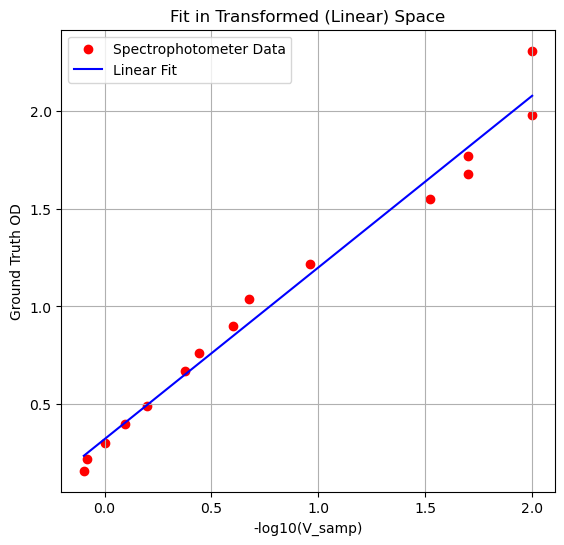

In [9]:
# Plot 1: The Linear Fit (shows how good the fit is)
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.scatter(x_transformed, Ground_Truth_OD_valid, label='Spectrophotometer Data', color='red')
plt.plot(x_fit_line, y_fit_line, label='Linear Fit', color='blue')
plt.title('Fit in Transformed (Linear) Space')
plt.xlabel('-log10(V_samp)')
plt.ylabel('Ground Truth OD')
plt.legend()
plt.grid(True)

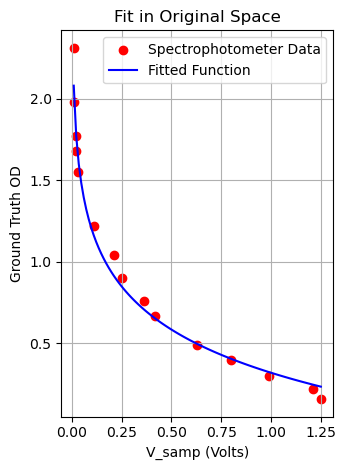

In [10]:
# Plot 2: The Final Curve (shows the function vs. your original data)
plt.subplot(1, 2, 2)
plt.scatter(V_samp, Ground_Truth_OD, label='Spectrophotometer Data', color='red')
plt.plot(v_samp_line, od_fit_curve, label='Fitted Function', color='blue')
plt.title('Fit in Original Space')
plt.xlabel('V_samp (Volts)')
plt.ylabel('Ground Truth OD')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Streaming Mode**

In [2]:
import serial
import serial.tools.list_ports
import pandas as pd
import numpy as np
import time
from datetime import datetime

from bokeh.plotting import figure, show
# --- MODIFIED: Added TextInput ---
from bokeh.models import ColumnDataSource, Button, Div, TextInput
from bokeh.layouts import column, row
from bokeh.io import output_notebook, show

output_notebook()

# --- 1. USER-PROVIDED FUNCTIONS ---

def find_arduino(port=None):
    """Get the name of the port that is connected to Arduino."""
    if port is None:
        ports = serial.tools.list_ports.comports()
        for p in ports:
            if p.manufacturer is not None and "Arduino" in p.manufacturer:
                port = p.device
    return port

def handshake_arduino(
    arduino, sleep_time=1, print_handshake_message=False, handshake_code=0
):
    """Make sure connection is established by sending
    and receiving bytes."""
    arduino.close()
    arduino.open()
    time.sleep(sleep_time)
    timeout = arduino.timeout
    arduino.timeout = 2
    _ = arduino.read_all()
    arduino.write(bytes([handshake_code]))
    handshake_message = arduino.read_until()
    arduino.write(bytes([handshake_code]))
    handshake_message = arduino.read_until()
    if print_handshake_message:
        print("Handshake message: " + handshake_message.decode())
    arduino.timeout = timeout

# --- 2. BOKEH APP GLOBALS ---

CALIB_SLOPE = 1.0022
CALIB_INTERCEPT = 0.3013

app_state = {
    'serial_connection': None,
    'recorded_data': [], 
    'periodic_callback': None,
    'arduino_port': find_arduino() 
}

# --- MODIFIED: Added global vars for new widgets ---
app_doc = None
connect_button = None
status_div = None
sampling_input = None # For the new input box

# --- Data Sources ---
live_source = ColumnDataSource(data={'time': [], 'od': [], 'raw_voltage': []})
bookmark_source = ColumnDataSource(data={'time': [], 'od': []})


# --- 3. CORE UPDATE FUNCTION (No changes here) ---
def update_data():
    if app_state['serial_connection'] is None or not app_state['serial_connection'].is_open:
        return 
    
    try:
        line = app_state['serial_connection'].readline().decode('utf-8').strip()
        if not line:
            return
        
        raw_adc = int(line)
        V_sample = (raw_adc / 1023.0) * 5.0
        
        V_sample_safe = max(V_sample, 1e-9)
        od = CALIB_SLOPE * (-np.log10(V_sample_safe)) + CALIB_INTERCEPT
        now = datetime.now()
        
        live_source.stream({
            'time': [now],
            'od': [od],
            'raw_voltage': [V_sample]
        })
        
    except (serial.SerialException, ValueError, TypeError) as e:
        status_div.text = f"Read error: {e}"
        pass

# --- 4. WIDGET CALLBACK FUNCTIONS ---

# --- MODIFIED: connect_button_callback ---
def connect_button_callback():
    port = app_state['arduino_port']
    if port is None:
        status_div.text = "Error: Could not find Arduino. Is it plugged in?"
        return

    # --- NEW: Get and validate the sampling interval ---
    try:
        interval_ms = int(sampling_input.value)
    except ValueError:
        status_div.text = "Error: Sampling Interval must be a valid number (e.g., 50)."
        return
    
    if interval_ms < 20: # 20ms is a safe minimum (50Hz)
        status_div.text = "Error: Interval must be at least 20ms."
        return
    # --- END NEW SECTION ---

    try:
        ser = serial.Serial(port, 115200, timeout=1)
        handshake_arduino(ser, handshake_code=83) 
        
        app_state['serial_connection'] = ser
        
        # --- MODIFIED: Use interval_ms from the input box ---
        app_state['periodic_callback'] = app_doc.add_periodic_callback(update_data, interval_ms)
        
        status_div.text = f"Connected to {port}! Streaming every {interval_ms}ms."
        connect_button.label = "Disconnect"
        
    except serial.SerialException as e:
        status_div.text = f"Error: Could not open {port}. {e}"

def disconnect_button_callback():
    if app_state['periodic_callback']:
        app_doc.remove_periodic_callback(app_state['periodic_callback'])
        app_state['periodic_callback'] = None
    
    if app_state['serial_connection']:
        app_state['serial_connection'].write(b'X') 
        app_state['serial_connection'].close()
        app_state['serial_connection'] = None
    
    status_div.text = "Disconnected."
    connect_button.label = "Connect"

def handle_connect_toggle():
    if connect_button.label == "Connect":
        connect_button_callback()
    else:
        disconnect_button_callback()

def record_timestamp_callback():
    if not live_source.data['time']:
        status_div.text = "Error: No data streaming. Cannot record."
        return

    last_time = live_source.data['time'][-1]
    last_od = live_source.data['od'][-1]
    
    bookmark_source.stream({'time': [last_time], 'od': [last_od]})
    
    app_state['recorded_data'].append({
        'timestamp': last_time,
        'optical_density': last_od
    })
    status_div.text = f"Recorded! OD = {last_od:.3f}"


def save_csv_callback():
    saved_files = []
    now_str = datetime.now().strftime('%Y%m%d_%H%M%S')
    
    # 1. Save recorded timestamps (as before)
    if app_state['recorded_data']:
        df_recorded = pd.DataFrame(app_state['recorded_data'])
        filename = f"od_recorded_timestamps_{now_str}.csv"
        df_recorded.to_csv(filename, index=False)
        saved_files.append(filename)

    # 2. NEW: Save full stream data
    if live_source.data['time']:
        # We need to copy the data, as it might be updated while saving
        stream_data = live_source.data.copy()
        df_stream = pd.DataFrame(stream_data)
        filename = f"od_stream_data_{now_str}.csv"
        df_stream.to_csv(filename, index=False)
        saved_files.append(filename)

    # 3. Report status
    if not saved_files:
        status_div.text = "No data to save."
    else:
        status_div.text = f"Saved data to: {', '.join(saved_files)}"

# --- 5. BOKEH DOCUMENT SETUP FUNCTION ---
def make_document(doc):
    # ---  Added sampling_input to globals ---
    global app_doc, connect_button, status_div, sampling_input
    app_doc = doc
    
    # --- Define Widgets ---
    port_display_text = f"Arduino found at: {app_state['arduino_port']}"
    if app_state['arduino_port'] is None:
        port_display_text = "No Arduino found. Please connect and re-run cell."
        
    port_info_div = Div(text=port_display_text)
    
    connect_button = Button(label="Connect", button_type="success")
    
    # --- Define sampling_input widget ---
    sampling_input = TextInput(value="50", title="Sampling Interval (ms):", width=150)
    
    record_button = Button(label="Record Timestamp", button_type="warning")
    # --- Changed button label ---
    save_button = Button(label="Save All Data to CSV", button_type="default")
    
    status_div = Div(text="Disconnected. Click 'Connect' to start.")

    # --- Define Plot ---
    plot = figure(
        title="Live Optical Density (OD) Stream",
        x_axis_type="datetime",
        x_axis_label="Time",
        y_axis_label="Optical Density (OD)",
        height=350,
        sizing_mode="stretch_width"
    )
    plot.line(x='time', y='od', source=live_source, legend_label="Live OD")
    plot.scatter(x='time', y='od', source=bookmark_source, 
                 legend_label="Recorded Timestamps", color="red", size=8)
    plot.legend.location = "top_left"

    # --- Attach Callbacks ---
    connect_button.on_click(handle_connect_toggle)
    record_button.on_click(record_timestamp_callback)
    save_button.on_click(save_csv_callback)

    # --- Create Layout ---
    # --- MODIFIED: Added sampling_input to the row ---
    controls_row1 = row(port_info_div, connect_button, sampling_input)
    controls_row2 = row(record_button, save_button)
    layout = column(controls_row1, controls_row2, status_div, plot)

    doc.add_root(layout)
    doc.title = "Arduino Spectrophotometer"


# --- 6. RUN THE APP ---
show(make_document, notebook_url="localhost:8888")

Loading BokehJS ...

ERROR:tornado.application:Uncaught exception GET /autoload.js?bokeh-autoload-element=d077c160-87bc-410a-bdfc-e7833ed5a86f&bokeh-absolute-url=http://localhost:62655&resources=none (127.0.0.1)
HTTPServerRequest(protocol='http', host='localhost:62655', method='GET', uri='/autoload.js?bokeh-autoload-element=d077c160-87bc-410a-bdfc-e7833ed5a86f&bokeh-absolute-url=http://localhost:62655&resources=none', version='HTTP/1.1', remote_ip='127.0.0.1')
Traceback (most recent call last):
  File "C:\Users\gaboz\AppData\Roaming\Python\Python313\site-packages\tornado\web.py", line 1790, in _execute
    result = await result
             ^^^^^^^^^^^^
  File "C:\Users\gaboz\miniconda3\envs\be189\Lib\site-packages\bokeh\server\views\autoload_js_handler.py", line 68, in get
    session = await self.get_session()
              ^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\gaboz\miniconda3\envs\be189\Lib\site-packages\bokeh\server\views\session_handler.py", line 145, in get_session
    session = await self.appli